# 02 — Modelagem (regressão: `NU_NOTA_MT`, ENEM 2025)

Pipeline com a biblioteca `machinelearning-mnpkllps`:

1. **Dados e análise exploratória** → 2. **Pré-processamento** → 3. **Modelos** → 4. **Validação cruzada** → 5. **Avaliação final no teste** → 6. **Interpretação**

Entrada: `data/treino.csv` e `data/teste.csv` (gerados pelo notebook 01). O teste só é usado na etapa 5.

In [2]:
from importlib.metadata import version # version(package) returns the installed version of a package, so the output records which library version produced the results

import numpy as np
import matplotlib.pyplot as plt

from machinelearning_mnpkllps import metricas
from machinelearning_mnpkllps.NeuralNetwork import NeuralNetwork
from machinelearning_mnpkllps.Regressao import MinimosQuadrados, Ridge
from machinelearning_mnpkllps.Reamostragem import KFold
from machinelearning_mnpkllps.preprocessing import StandardScaler

SEED = 20251
K = 5          # number of folds
print("library version:", version("machinelearning-mnpkllps"))

library version: 0.2.14


## 1. Dados e análise exploratória

train = 6400 rows, test = 1600 rows


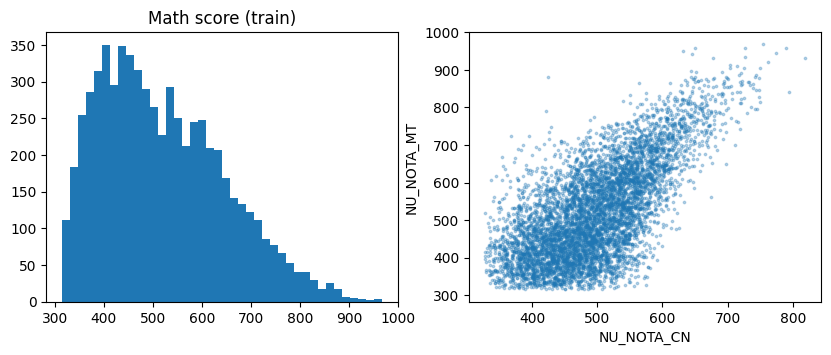

correlation of NU_NOTA_CN with NU_NOTA_MT: 0.68
correlation of NU_NOTA_CH with NU_NOTA_MT: 0.66
correlation of NU_NOTA_LC with NU_NOTA_MT: 0.66
correlation of NU_NOTA_REDACAO with NU_NOTA_MT: 0.56


In [3]:
Target = "NU_NOTA_MT"
Numeric = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_REDACAO"]
Categorical = ["TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC", "SG_UF_ESC", "TP_LINGUA"] # school administration (federal, state...), school location (urban/rural), school state and foreign language

def _read(path):
	# np.genfromtxt reads a CSV into a numpy structured array. names=True takes the column names from the header, so a column can be accessed as data["COLUMN_NAME"]; dtype=None lets numpy infer the type of each column (number or text)
	return np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8")

train, test = _read("../data/treino.csv"), _read("../data/teste.csv")
ytr, yte = train[Target].astype(float), test[Target].astype(float) # astype(float) converts the column into a float array
print(f"train = {len(ytr)} rows, test = {len(yte)} rows")

# Only the training data is used here; the test set stays untouched until the final evaluation.
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5)) # a figure with 1 row and 2 columns of plots: ax[0] and ax[1]
ax[0].hist(ytr, bins=40)
ax[0].set_title("Math score (train)")
ax[1].scatter(train["NU_NOTA_CN"], ytr, s=3, alpha=0.3) # s is the size of the points and alpha their transparency, so overlapping points stay visible
ax[1].set_xlabel("NU_NOTA_CN"); ax[1].set_ylabel("NU_NOTA_MT")
plt.show()

for c in Numeric:
	# np.corrcoef(a, b) returns the 2 x 2 correlation matrix of a and b; the element [0, 1] is the correlation between a and b
	print(f"correlation of {c} with {Target}: {np.corrcoef(train[c].astype(float), ytr)[0, 1]:.2f}")

## 2. Pré-processamento

* **Notas** (numéricas): padronizadas com o `StandardScaler` da biblioteca **dentro do `fit` de cada modelo** (`with_scaling`, na etapa 3). Na validação cruzada, a média e o desvio vêm só das dobras de treino, então a dobra de validação não vaza para a padronização; na avaliação final, vêm de todo o treino.
* **Categóricas**: viram colunas 0/1 (dummies). A categoria mais frequente do treino é a referência e não ganha coluna; uma categoria inédita no teste cai na referência.

In [4]:
# The dummies are built by hand instead of using ColumnCategoricalEncoder from our preprocessing module because:
# 1. With drop_first=True, our encoder drops the first category in sorted order (np.unique sorts them), e.g. "AC" for the states.
# Here we want the most frequent category of the training set as the baseline, so each dummy coefficient compares a category with the most common case.
# 2. Our encoder raises ValueError when the test set has a category that was not seen in fit. With 27 states and some rare categories,
# a category may appear only in the test set. Here such a row simply gets 0 in all its dummies, i.e., it falls into the baseline category.
# The logic is the same one used inside CategoricalEncoder.transform (comparing a column vector with a row vector), only with these two changes.

def get_column(sample, c):
	col = sample[c]
	# dtype.kind is a one-letter code of the array type: 'f' float, 'i' integer, 'U' text. Code columns (e.g. TP_LINGUA = 0 or 1) may be read as float, so they become int to give clean category names (1 instead of 1.0)
	return col.astype(int) if col.dtype.kind == "f" else col

# categories of each variable, from the most to the least frequent; the first one (baseline) is dropped
categories = {}
for c in Categorical:
	values, counts = np.unique(get_column(train, c), return_counts=True) # np.unique returns the sorted distinct values and, with return_counts=True, how many times each one appears
	categories[c] = values[np.argsort(-counts)][1:] # np.argsort(-counts) gives the indices that sort counts in decreasing order (sorting -counts ascending = sorting counts descending); [1:] drops the most frequent category, the baseline, starting from index 1

# names of the columns of the design matrix, used later to interpret the Ridge coefficients
feature_names = Numeric + [f"{c}={v}" for c in Categorical for v in categories[c]] # f"{c}={v}" is a formatted string, e.g. "TP_LINGUA=1" for the dummy of the first foreign language

def build_design_matrix(sample):
	"""Returns the design matrix of a sample: the scores (not standardized yet) followed by the dummy columns"""
	# np.column_stack joins the score columns side by side into a (n_samples, 4) matrix.
	# The scores are standardized later, inside the fit of each model (see with_scaling), so that the mean and std only come from the data the model is trained on
	scores = np.column_stack([sample[c] for c in Numeric]).astype(float)
	# Indexing with None adds a new axis: column[:, None] has shape (n, 1) and categories[c][None, :] has shape (1, K-1).
	# Comparing them with == gives a (n, K-1) boolean matrix, True where the row has that category. The baseline or a category not seen in training gives a row of all False. Same logic as CategoricalEncoder.transform, but with the two changes explained above.
	dummies = np.column_stack([get_column(sample, c)[:, None] == categories[c][None, :] for c in Categorical])
	return np.column_stack([scores, dummies.astype(float)]) # astype(float) turns True/False into 1/0

X_train, X_test = build_design_matrix(train), build_design_matrix(test)
print("design matrix:", X_train.shape, "(train),", X_test.shape, "(test)")

design matrix: (6400, 35) (train), (1600, 35) (test)


## 3. Modelos

Comparamos quatro modelos: **baseline** (prevê a média), **Mínimos Quadrados**, **Ridge** e **rede neural** (duas arquiteturas × duas taxas de aprendizado). O `KFold` da biblioteca pede uma classe com `fit` e `predict`; o baseline e a rede precisam de uma classe pequena para isso. Na rede, `y` é padronizado para o treino e a previsão volta para a escala de pontos. Os modelos que usam as notas passam por `with_scaling`, que faz a padronização dentro do `fit`.

In [5]:
class MeanBaseline:
	"""Always predicts the mean of y in the training data. Any useful model must do better than this."""
	def __init__(self, hip=None): pass # KFold may create the class with a hyperparameter; the baseline has none, so it is ignored
	def fit(self, X, y): self.m = y.mean(); return self
	def predict(self, X): return np.full(len(X), self.m) # np.full(n, value) creates an array of size n filled with value


def make_network(hidden_layers, lr, epochs):
	"""Wraps the library's neural network into a class with fit/predict, as KFold requires (the network expects X with one sample per column)"""
	# KFold receives a class and creates a new object for each fold, so we cannot give it an already configured object.
	# This function builds and returns a new class that remembers hidden_layers, lr and epochs (a closure), so each configuration of the grid becomes its own class
	class Network:
		def __init__(self, hip=None): pass

		def fit(self, X, y):
			# y is standardized for training: with tanh and small initial weights, the network learns much better with targets around 0 than with scores around 500
			self.m, self.s = y.mean(), y.std()
			# [X.shape[1], *hidden_layers, 1]: an input layer with one neuron per feature, the hidden layers (* unpacks the tuple into the list) and one output neuron
			self.net = NeuralNetwork([X.shape[1], *hidden_layers, 1], "tanh", "identity",
					bias_interval=(-0.1, 0.1), weight_interval=(-0.1, 0.1), seed=SEED)
			# X.T transposes X to (n_features, n_samples) and reshape(1, -1) turns y into a (1, n_samples) row, the format the network expects
			self.net.fit(X.T, ((y - self.m) / self.s).reshape(1, -1),
					learn_rate=lr, batch=64, epochs=epochs)
			return self

		def predict(self, X):
			# prevision returns a (1, n_samples) matrix; ravel() flattens it into a 1D vector, and * s + m undoes the standardization, going back to points
			return self.net.prevision(X.T).ravel() * self.s + self.m
	return Network


def with_scaling(model_class):
	"""Returns a version of model_class that standardizes the score columns inside fit, using only the data it is trained on"""
	# Inside KFold, fit only receives the training folds, so the mean and std never see the validation fold (no data leakage).
	# In the final evaluation, fit receives the whole training set, so the test set is transformed with the training mean and std.
	n_scores = len(Numeric) # the scores are the first columns of the design matrix; the other columns are the 0/1 dummies, which are not standardized
	class Scaled:
		def __init__(self, hip=None):
			self.model = model_class(hip) if hip is not None else model_class() # the original model, created with or without its hyperparameter

		def _scale(self, X):
			X = X.copy() # copy, so that the matrix given by KFold is not modified
			X[:, :n_scores] = self.scaler.transform(X[:, :n_scores]) # X[:, :n_scores] selects all the rows and the first n_scores columns
			return X

		def fit(self, X, y):
			self.scaler = StandardScaler().fit(X[:, :n_scores]) # mean and std of the data given to fit only
			self.model.fit(self._scale(X), y)
			return self

		def predict(self, X):
			return self.model.predict(self._scale(X)) # new data is transformed with the mean and std learned in fit
	return Scaled

## 4. Validação cruzada (só no treino)

K-fold com K = 5 e a mesma semente para todos, então todas as configurações são avaliadas nas mesmas dobras. Em cada modelo, fica a configuração com menor RMSE. O teste não participa da escolha.

In [6]:
# For each model family, a list of (class, hyperparameter, description).
# with_scaling(...) is only skipped for the baseline, which does not use X
grids = {
	"Baseline":         [(MeanBaseline, None, "mean")],
	"MinimosQuadrados": [(with_scaling(MinimosQuadrados), None, "-")],
	"Ridge":            [(with_scaling(Ridge), a, f"alpha={a}") for a in (1e-3, 1e-2, 1e-1)],
	"NeuralNetwork":    [(with_scaling(make_network(h, lr, 50)), None, f"layers={h}, lr={lr}")
						for h in ((16,), (32, 16)) for lr in (0.01, 0.05)],
}

best = {}
for family, options in grids.items(): # .items() goes through the (key, value) pairs of the dictionary
	results = []
	for cls, hip, description in options:
		# KFold(...).folds() returns the mean MSE over the K folds; the square root turns it into RMSE, in points like the score.
		# The same seed gives the same folds for every configuration, so all of them are compared on the same data
		rmse = np.sqrt(KFold(cls, X_train, ytr, k=K, hip=hip, seed=SEED).folds())
		results.append((rmse, cls, hip, description))
		print(f"{family:17s} {description:26s} CV-RMSE = {rmse:.2f}") # :17s pads the text to 17 characters, to align the columns
	best[family] = min(results, key=lambda r: r[0]) # key=lambda r: r[0] makes min compare the tuples only by their first element, the RMSE

Baseline          mean                       CV-RMSE = 126.35
MinimosQuadrados  -                          CV-RMSE = 79.07
Ridge             alpha=0.001                CV-RMSE = 79.05
Ridge             alpha=0.01                 CV-RMSE = 79.09
Ridge             alpha=0.1                  CV-RMSE = 79.60
NeuralNetwork     layers=(16,), lr=0.01      CV-RMSE = 76.87
NeuralNetwork     layers=(16,), lr=0.05      CV-RMSE = 76.12
NeuralNetwork     layers=(32, 16), lr=0.01   CV-RMSE = 76.70
NeuralNetwork     layers=(32, 16), lr=0.05   CV-RMSE = 76.15


## 5. Avaliação final no teste (uma única vez)

Cada modelo escolhido é reajustado em todo o treino e avaliado no teste.

In [7]:
models = {}
for family, (rmse_cv, cls, hip, description) in best.items():
	# refits the chosen configuration on the whole training set; fit returns self, so it can be chained right after creating the object
	model = (cls(hip) if hip is not None else cls()).fit(X_train, ytr)
	models[family] = model
	p = model.predict(X_test)
	# :6.2f writes the number with 2 decimals in a field of 6 characters; two f-strings next to each other are joined into a single string
	print(f"{family:17s} CV-RMSE={rmse_cv:6.2f} | test: RMSE={metricas.RMSE(p, yte):6.2f}"
		f"  MAE={metricas.MAE(p, yte):6.2f}  R2={metricas.R2(p, yte):.3f}")

Baseline          CV-RMSE=126.35 | test: RMSE=125.51  MAE=103.04  R2=-0.001
MinimosQuadrados  CV-RMSE= 79.07 | test: RMSE= 78.38  MAE= 62.05  R2=0.609
Ridge             CV-RMSE= 79.05 | test: RMSE= 78.38  MAE= 62.05  R2=0.610
NeuralNetwork     CV-RMSE= 76.12 | test: RMSE= 75.33  MAE= 59.93  R2=0.639


## 6. Interpretação

Coeficientes do Ridge: nas notas, é a variação em pontos de MT para 1 desvio-padrão da nota; nas dummies, a diferença em pontos em relação à categoria de referência. São associações, não efeitos causais.

In [8]:
coef = models["Ridge"].model.coeficientes[1:]   # models["Ridge"] is the Scaled wrapper and .model is the Ridge inside it; coeficientes[0] is the intercept, the others follow the order of feature_names
print("10 largest coefficients (in absolute value):")
for i in np.argsort(-np.abs(coef))[:10]: # indices of the coefficients sorted by decreasing absolute value; [:10] keeps the first 10
	print(f"  {feature_names[i]:38s} {coef[i]:8.2f}")

10 largest coefficients (in absolute value):
  NU_NOTA_CN                                38.61
  TP_DEPENDENCIA_ADM_ESC=4                  36.18
  SG_UF_ESC=AC                             -35.53
  SG_UF_ESC=RR                             -33.08
  SG_UF_ESC=PA                             -32.01
  TP_DEPENDENCIA_ADM_ESC=1                  31.75
  SG_UF_ESC=TO                             -28.52
  SG_UF_ESC=AP                             -26.70
  NU_NOTA_CH                                25.79
  SG_UF_ESC=PB                             -24.16


## Limites

* Só entram participantes que informaram a escola e fizeram as 4 provas com redação válida: o recorte não representa todos os participantes.
* A base não tem renda, raça ou sexo; os coeficientes não indicam causalidade.
* A lista de categorias e a categoria de referência das dummies vêm de todo o treino, e não de cada dobra. A lista é conhecida de antemão (estados e códigos do INEP), e trocar a referência não muda as previsões dos Mínimos Quadrados (só reescreve os mesmos coeficientes); no Ridge e na rede o efeito é mínimo.